# MyUsvEnv 环境测试

对 USV 多目标路径规划环境进行全面测试，包括：
1. 环境初始化与配置
2. 环境可视化
3. 观测空间检查
4. 仿真运行 (随机动作)
5. 路径绘制

In [7]:
import sys, os
# 添加项目根目录到路径
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import matplotlib.pyplot as plt
from my_USV_Env import MyUsvEnv, ObstacleShape

print("模块导入成功")

模块导入成功


## 1. 环境初始化与信息查看

In [8]:
# 创建环境实例
env = MyUsvEnv(
    num_targets=5,
    num_obstacles=9,
    dt=0.5,
    seed=42,
    record_flag=False,
    usv_length=3.0,
    usv_width=1.5,
    use_random_shapes=True,
    current_type="generated"
)

# 打印环境信息
info = env.get_environment_info()
print(f"目标数量: {info['num_targets']}")
print(f"障碍物数量: {info['num_obstacles']}")
print(f"随机种子: {info['seed']}")
print(f"起始位置: ({info['start_pos'][0]:.1f}, {info['start_pos'][1]:.1f})")
print(f"USV尺寸: 长={info['usv_size']['length']}m, 宽={info['usv_size']['width']}m")

print("\n--- 目标信息 ---")
for i, t in enumerate(info['targets']):
    print(f"  目标{i}: ({t['x']:.1f}, {t['y']:.1f}), 半径={t['radius']:.1f}")

print("\n--- 障碍物信息 ---")
for i, o in enumerate(info['obstacles']):
    shape_str = o['shape']
    pos_str = f"({o['x']:.1f}, {o['y']:.1f})"
    if shape_str == 'circle':
        print(f"  障碍物{i}: {shape_str} {pos_str}, R={o.get('radius', 'N/A')}")
    elif shape_str == 'rectangle':
        print(f"  障碍物{i}: {shape_str} {pos_str}, W={o.get('width','N/A')}, H={o.get('height','N/A')}")
    else:
        print(f"  障碍物{i}: {shape_str} {pos_str}")

print("\n--- 动作空间 ---")
print(f"  形状: {env.action_space.shape}, 范围: [{env.action_space.low}, {env.action_space.high}]")

print("\n--- 观测空间 ---")
for key, space in env.observation_space.spaces.items():
    print(f"  {key}: shape={space.shape}, dtype={space.dtype}")

目标数量: 5
障碍物数量: 9
随机种子: 42
起始位置: (23.3, 27.4)
USV尺寸: 长=3.0m, 宽=1.5m

--- 目标信息 ---
  目标0: (41.9, 13.5), 半径=3.0
  目标1: (20.4, 91.8), 半径=3.0
  目标2: (30.4, 90.0), 半径=3.0
  目标3: (37.0, 61.3), 半径=3.0
  目标4: (57.8, 14.8), 半径=3.0

--- 障碍物信息 ---
  障碍物0: polygon (69.0, 29.7)
  障碍物1: rectangle (51.6, 45.6), W=10.077207962772587, H=7.282970263056656
  障碍物2: polygon (47.2, 68.3)
  障碍物3: rectangle (20.0, 71.9), W=12.29655786717672, H=5.766051652012701
  障碍物4: circle (81.2, 67.4), R=4.391009770739207
  障碍物5: polygon (70.2, 63.2)
  障碍物6: rectangle (74.8, 48.2), W=7.674319443136223, H=7.992713510560965
  障碍物7: rectangle (33.1, 34.4), W=6.566070253538038, H=7.974640227800512
  障碍物8: rectangle (18.0, 40.6), W=10.266937614212406, H=4.152590972000592

--- 动作空间 ---
  形状: (2,), 范围: [[-1. -1.], [1. 1.]]

--- 观测空间 ---
  o_current: shape=(4,), dtype=float32
  o_detector: shape=(15,), dtype=float32
  o_usv: shape=(7,), dtype=float32
  targets: shape=(15,), dtype=float32


## 2. 环境可视化

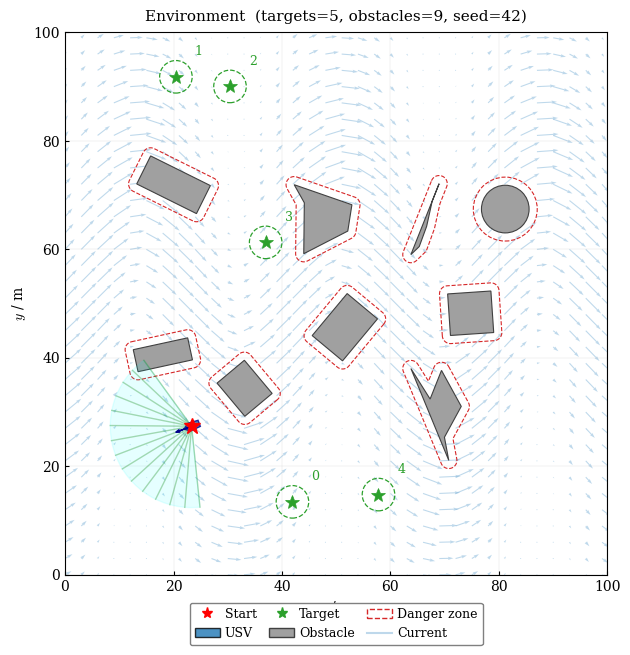

In [9]:
# 可视化初始环境（含海流、障碍物、目标）
env.visualize_env()

## 3. 观测空间测试

重置环境并检查观测值的形状和数值范围。

In [10]:
# 重置环境并检查观测值
obs = env.reset(seed=42)

print("--- 观测值检查 ---")
for key, val in obs.items():
    print(f"  {key}: shape={val.shape}, min={val.min():.4f}, max={val.max():.4f}, dtype={val.dtype}")

print("\n--- 详细观测值 ---")
print(f"  o_usv (自身状态): {obs['o_usv']}")
print(f"    [x_norm, y_norm, u_norm, v_norm, r_norm, sin(heading), cos(heading)]")
print(f"  o_current (海流):  {obs['o_current']}")
print(f"  o_detector (传感器): {obs['o_detector']}")
print(f"  targets (目标):     {obs['targets']}")

# 验证是否有 NaN
has_nan = any(np.isnan(v).any() for v in obs.values())
print(f"\n包含 NaN: {has_nan} {'异常！' if has_nan else '正常'}")

--- 观测值检查 ---
  o_usv: shape=(7,), min=-0.9341, max=0.2739, dtype=float32
  targets: shape=(15,), min=0.0000, max=0.9181, dtype=float32
  o_current: shape=(4,), min=-0.6770, max=0.7360, dtype=float32
  o_detector: shape=(15,), min=1.0000, max=1.0000, dtype=float32

--- 详细观测值 ---
  o_usv (自身状态): [ 0.23330599  0.27388644  0.          0.          0.         -0.3570106
 -0.93410033]
    [x_norm, y_norm, u_norm, v_norm, r_norm, sin(heading), cos(heading)]
  o_current (海流):  [ 0.7359865 -0.6769963 -0.6769963  0.7359865]
  o_detector (传感器): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
  targets (目标):     [0.41922238 0.13450949 0.         0.20439301 0.918102   0.
 0.30409604 0.9003566  0.         0.36985984 0.61285514 0.
 0.57786524 0.1479168  0.        ]

包含 NaN: False 正常


## 4. 仿真运行测试（随机动作）

使用随机动作运行仿真 2000 步，统计碰撞次数、目标到达情况和 USV 运动轨迹。

环境重置完成


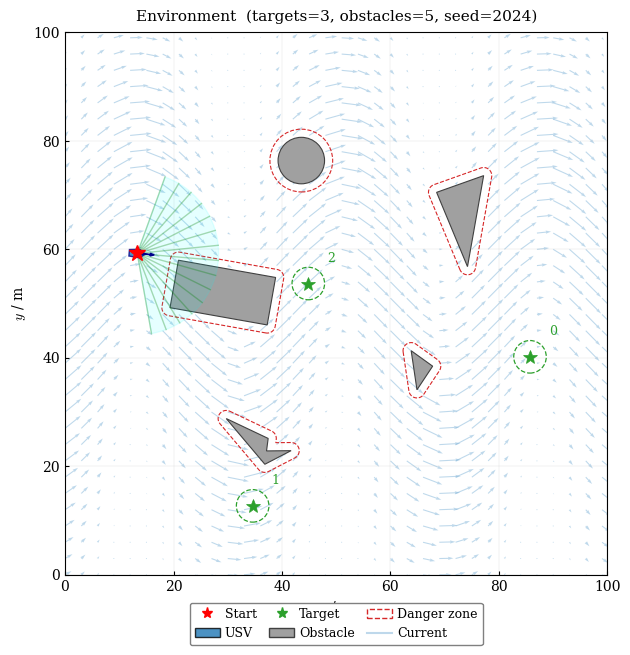

  Step 964: 到达目标 1

--- 仿真统计 ---
  总步数: 2000
  碰撞次数: 0
  到达目标: 1/3
  最终位置: (0.00, 57.18)
  位置范围: X=[0.0, 34.3], Y=[0.0, 60.1]


In [11]:
# 仿真运行：随机动作
env_sim = MyUsvEnv(
    num_targets=3,
    num_obstacles=5,
    seed=2024,
    record_flag=True,
    use_random_shapes=True,
    current_type="generated"
)

# 清理旧的路径文件
path_file = "usv_path_points_test.csv"
if os.path.exists(path_file):
    os.remove(path_file)

obs = env_sim.reset()
print("环境重置完成")
env_sim.visualize_env()

# 选择第一个未访问目标作为子目标
goal_pos = np.array([env_sim.targets[0].x, env_sim.targets[0].y])

max_steps = 2000
collision_count = 0
positions = []  # 记录轨迹

for step_i in range(max_steps):
    # 随机动作
    action = env_sim.action_space.sample()
    obs, done, crush, truncated, info = env_sim.step(action, goal_pos)
    
    positions.append(env_sim.current_pos.copy())
    
    if info['collision']:
        collision_count += 1
    
    # 动态切换子目标
    if info['reached_targets']:
        for idx in info['reached_targets']:
            print(f"  Step {step_i}: 到达目标 {idx}")
        # 找下一个未访问目标
        for j in range(env_sim.num_targets):
            if info['target_status'][j] == 0:
                goal_pos = np.array([env_sim.targets[j].x, env_sim.targets[j].y])
                break
    
    if done:
        print(f"  Step {step_i}: 子目标完成")
        break

env_sim.close_writer()

positions = np.array(positions)
visited = int(info['target_status'].sum())
print(f"\n--- 仿真统计 ---")
print(f"  总步数: {step_i + 1}")
print(f"  碰撞次数: {collision_count}")
print(f"  到达目标: {visited}/{env_sim.num_targets}")
print(f"  最终位置: ({env_sim.current_pos[0]:.2f}, {env_sim.current_pos[1]:.2f})")
print(f"  位置范围: X=[{positions[:,0].min():.1f}, {positions[:,0].max():.1f}], "
      f"Y=[{positions[:,1].min():.1f}, {positions[:,1].max():.1f}]")

## 5. 路径绘制

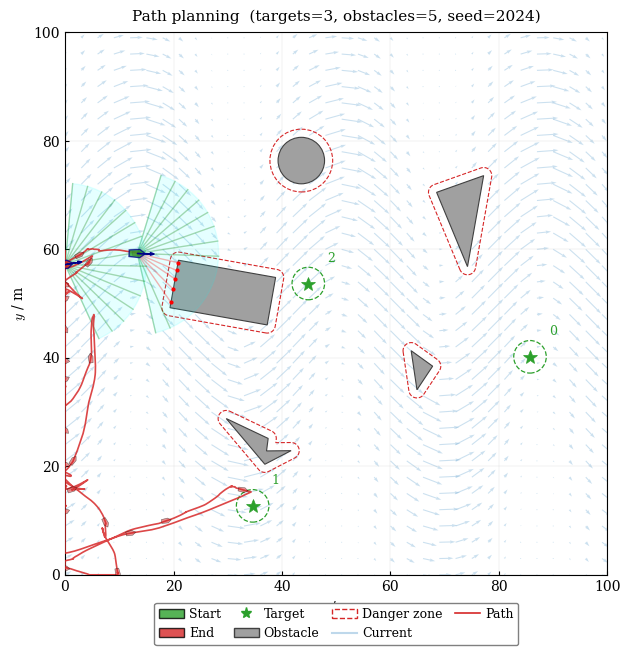

In [12]:
# 使用环境内置函数绘制仿真路径
if os.path.exists(path_file):
    env_sim.draw_path(csv_file=path_file, ifshow=True, show_usv_shape=True, usv_interval=100)
else:
    print("未找到路径记录文件")

## 6. 传感器与海流测试

--- 传感器信息 ---
  传感器范围: 15.0
  传感器FOV:  150°
  检测线数量: 15
  当前读数:   [15. 15. 15. 15. 15. 15. 15. 15. 15. 15. 15. 15. 15. 15. 15.]

--- 海流测试 ---
  (10,10): u=0.0259, v=0.0303, speed=0.0398, direction=49.5°
  (50,50): u=0.3050, v=-0.0000, speed=0.3050, direction=-0.0°
  (90,90): u=0.7422, v=-0.2112, speed=0.7716, direction=-15.9°
  (25,75): u=0.2317, v=-0.2794, speed=0.3630, direction=-50.3°


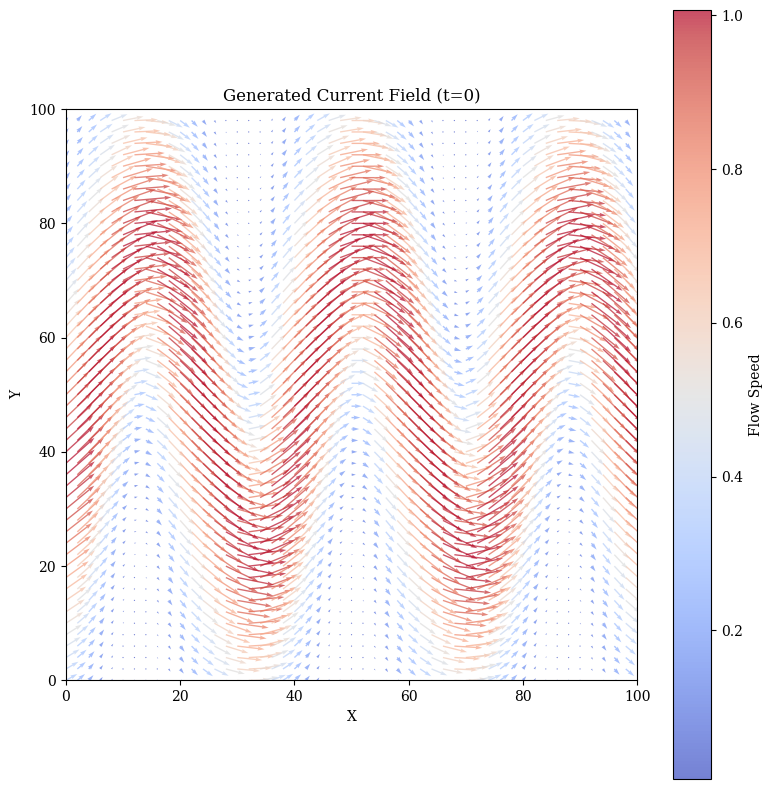

In [13]:
# 测试传感器读数
print("--- 传感器信息 ---")
print(f"  传感器范围: {env_sim.usv.sensor_range}")
print(f"  传感器FOV:  {np.degrees(env_sim.usv.sensor_fov):.0f}°")
print(f"  检测线数量: {env_sim.usv.num_detection_lines}")
print(f"  当前读数:   {np.array(env_sim.usv.sensor_readings).round(2)}")

# 测试海流场
print("\n--- 海流测试 ---")
test_points = [(10, 10), (50, 50), (90, 90), (25, 75)]
for px, py in test_points:
    fu, fv = env_sim.get_flow_velocity(px, py, t=0)
    speed = np.sqrt(fu**2 + fv**2)
    angle = np.degrees(np.arctan2(fv, fu))
    print(f"  ({px:2d},{py:2d}): u={fu:.4f}, v={fv:.4f}, speed={speed:.4f}, direction={angle:.1f}°")

# 可视化海流场
fig, ax = plt.subplots(figsize=(8, 8))
X, Y = np.meshgrid(np.arange(0, 100, 2), np.arange(0, 100, 2))
U_vis = np.zeros_like(X, dtype=float)
V_vis = np.zeros_like(Y, dtype=float)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        U_vis[i, j], V_vis[i, j] = env_sim.get_flow_velocity(X[i, j], Y[i, j], t=0)

speed = np.sqrt(U_vis**2 + V_vis**2)
ax.quiver(X, Y, U_vis, V_vis, speed, cmap='coolwarm', alpha=0.7, scale=15)
ax.set_title("Generated Current Field (t=0)")
ax.set_xlabel("X"); ax.set_ylabel("Y")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_aspect('equal')
plt.colorbar(ax.collections[0], ax=ax, label='Flow Speed')
plt.tight_layout()
plt.show()

## 7. Reset 一致性测试

使用相同种子 reset 两次，验证环境状态是否完全一致。

In [14]:
# Reset 一致性验证
env_test = MyUsvEnv(num_targets=3, num_obstacles=5, seed=100, current_type="generated")

obs1 = env_test.reset(seed=100)
start1 = env_test.start_pos.copy()
targets1 = [(t.x, t.y) for t in env_test.targets]

obs2 = env_test.reset(seed=100)
start2 = env_test.start_pos.copy()
targets2 = [(t.x, t.y) for t in env_test.targets]

# 对比
start_match = np.allclose(start1, start2)
targets_match = all(np.allclose(t1, t2) for t1, t2 in zip(targets1, targets2))
obs_match = all(np.allclose(obs1[k], obs2[k]) for k in obs1.keys())

print(f"起始位置一致: {start_match} {'✅' if start_match else '❌'}")
print(f"目标位置一致: {targets_match} {'✅' if targets_match else '❌'}")
print(f"观测值一致:   {obs_match} {'✅' if obs_match else '❌'}")

if start_match and targets_match and obs_match:
    print("\nReset 一致性测试通过")
else:
    print("\nReset 一致性测试失败")

起始位置一致: True ✅
目标位置一致: True ✅
观测值一致:   True ✅

Reset 一致性测试通过


### 7. 海流动画测试

In [15]:
# 使用 seed=42 的环境测试动画（短时长，快速验证）
import os
save_path = os.path.join(os.getcwd(), "currents_animation_test.gif")
env.animate(duration=10, interval=100, save_path=save_path)

# 检查文件是否生成
if os.path.exists(save_path):
    size_kb = os.path.getsize(save_path) / 1024
    print(f"动画文件已生成: {save_path}")
    print(f"文件大小: {size_kb:.1f} KB")
else:
    print("动画文件未生成")

动画已保存至 d:\fileForWhile\USV-MuilTarget-path-plaaning\test\currents_animation_test.gif  (20 帧)
动画文件已生成: d:\fileForWhile\USV-MuilTarget-path-plaaning\test\currents_animation_test.gif
文件大小: 364.8 KB


### 8. USV 动态轨迹回放测试

In [ ]:
# 先用仿真环境跑一段轨迹并记录 CSV
env_anim = MyUsvEnv(
    num_targets=3, num_obstacles=5, seed=2024,
    record_flag=True, use_random_shapes=True, current_type="generated"
)

# step() 内部固定写入 usv_path_points_test.csv
anim_csv = "usv_path_points_test.csv"
if os.path.exists(anim_csv):
    os.remove(anim_csv)

obs = env_anim.reset()
goal = np.array([env_anim.targets[0].x, env_anim.targets[0].y])

for _ in range(500):
    action = env_anim.action_space.sample()
    obs, done, crush, trunc, info = env_anim.step(action, goal)
env_anim.close_writer()
print(f"轨迹已记录到 {anim_csv}，共 500 步")

# 回放动画并保存为 GIF（海流 + 轨迹同步）
gif_path = os.path.join(os.getcwd(), "usv_path_replay.gif")
env_anim.animate(
    csv_file=anim_csv,
    interval=40,
    save_path=gif_path,
    trail_length=0,
    speed=5
)

if os.path.exists(gif_path):
    size_kb = os.path.getsize(gif_path) / 1024
    print(f"回放动画已保存: {gif_path}  ({size_kb:.0f} KB)")
else:
    print("动画未生成")

d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


轨迹已记录到 usv_path_points_test.csv，共 500 步
动画已保存至 d:\fileForWhile\USV-MuilTarget-path-plaaning\test\usv_path_replay.gif
回放动画已保存: d:\fileForWhile\USV-MuilTarget-path-plaaning\test\usv_path_replay.gif  (1127 KB)


### 9. USV mpc控制动态轨迹回放测试

In [6]:
# MPC 评估回放: episode 6 (seed = 42 + 5 = 47)
env_mpc = MyUsvEnv(
    num_targets=3, num_obstacles=6, seed=42,
    record_flag=False, use_random_shapes=True,
    usv_length=3.0, usv_width=1.5,
    target_radius=3.0,
    obstacle_radius_range=(3.0, 10.0),
    current_type="generated"
)
env_mpc.reset(seed=47)  # episode 6 的布局

anim_csv = "../mpc_hrl_output_221/evaluation_results/eval_mpc/mpc_hrl_path_mpc_ep_6.csv"
gif_path = "../mpc_hrl_output_221/evaluation_results/eval_mpc/mpc_hrl_path_mpc_ep_6.gif"

env_mpc.animate(
    csv_file=anim_csv,
    interval=40,
    save_path=gif_path,
    trail_length=0,
    speed=5
)

if os.path.exists(gif_path):
    size_kb = os.path.getsize(gif_path) / 1024
    print(f"回放动画已保存: {gif_path}  ({size_kb:.0f} KB)")
else:
    print("动画未生成")

d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


动画已保存至 ../mpc_hrl_output_221/evaluation_results/eval_mpc/mpc_hrl_path_mpc_ep_6.gif  (226 帧)
回放动画已保存: ../mpc_hrl_output_221/evaluation_results/eval_mpc/mpc_hrl_path_mpc_ep_6.gif  (4432 KB)


### 9. USV RL控制动态轨迹回放测试

In [5]:
# RL 评估回放: episode 4 (seed = 42 + 3 = 45)
env_mpc = MyUsvEnv(
    num_targets=3, num_obstacles=6, seed=42,
    record_flag=False, use_random_shapes=True,
    usv_length=3.0, usv_width=1.5,
    target_radius=3.0,
    obstacle_radius_range=(3.0, 10.0),
    current_type="generated"
)
env_mpc.reset(seed=45)  # episode 4 的布局

anim_csv = "../mpc_hrl_output_221/evaluation_results/eval_rl/mpc_hrl_path_rl_ep_4.csv"
gif_path = "../mpc_hrl_output_221/evaluation_results/eval_rl/mpc_hrl_path_rl_ep_4.gif"

env_mpc.animate(
    csv_file=anim_csv,
    interval=40,
    save_path=gif_path,
    trail_length=0,
    speed=5
)

if os.path.exists(gif_path):
    size_kb = os.path.getsize(gif_path) / 1024
    print(f"回放动画已保存: {gif_path}  ({size_kb:.0f} KB)")
else:
    print("动画未生成")

d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:235: UserWarning: WARN: Box low's precision lowered by casting to float32, current low.dtype=float64
  gym.logger.warn(
d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:305: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


动画已保存至 ../mpc_hrl_output_221/evaluation_results/eval_rl/mpc_hrl_path_rl_ep_4.gif  (377 帧)
回放动画已保存: ../mpc_hrl_output_221/evaluation_results/eval_rl/mpc_hrl_path_rl_ep_4.gif  (7287 KB)
